# PCA SEEDS

In [1]:
# import libraries/packages
#%pip install plotly
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import plotly.express as px

In [2]:
# first we will download the data directly from the web
data_url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00236/seeds_dataset.txt'

# Download data directly from UCI repo
data_url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00236/seeds_dataset.txt'

data_cols = ['area', 'perimeter', 'compactness', 'length', 'width', 'asym', 'groove', 'variety']

# sep=r'\s+' handles varying tabs/spaces in the dataset file
data = pd.read_csv(data_url, sep=r'\s+', on_bad_lines='skip', names=data_cols, index_col=None)
data

,area,perimeter,compactness,length,width,asym,groove,variety
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1
...,...,...,...,...,...,...,...,...
205,12.19,13.20,0.8783,5.137,2.981,3.631,4.870,3
206,11.23,12.88,0.8511,5.140,2.795,4.325,5.003,3
207,13.20,13.66,0.8883,5.236,3.232,8.315,5.056,3
208,11.84,13.21,0.8521,5.175,2.836,3.598,5.044,3


In [3]:
scaler = StandardScaler()
scaler.fit(data)
data_scaled = scaler.transform(data)

pca = PCA(n_components = 0.95) # we tell it the target percentage of cumulative variance to preserve.

pca.fit(data_scaled)
components = pca.fit_transform(data_scaled)

print(pca)

PCA(n_components=0.95)


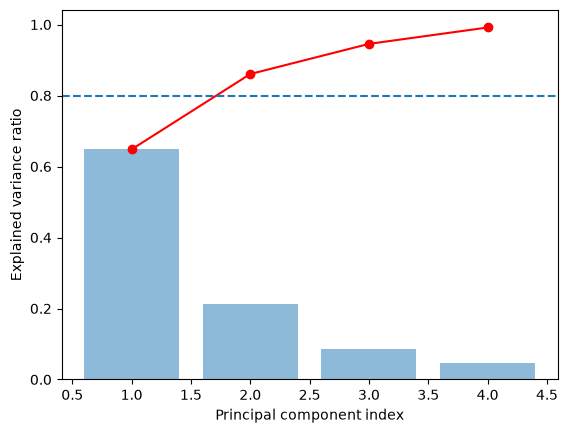

In [4]:
fig, ax = plt.subplots()
# Create an index array corresponding to each principal component (1 through N).
xi = range(1, pca.n_components_+1) 
y = np.cumsum(pca.explained_variance_ratio_)

# The Principal Component Index (x-axis) represents the rank order of the newly created orthogonal axes (components) in Principal Component Analysis (PCA).
# In this  specific dataset, PCA identified a given number of principal components.

# Individual variance
plt.bar(xi, pca.explained_variance_ratio_, alpha=0.5, align='center',label='Individual explained variance')

# Cumulative variance
plt.plot(xi, y , '-o', label='Cumulative explained variance',color='red')

# 80% Variance threshold
plt.axhline(0.8, linestyle = '--') # Draws a dashed horizontal threshold line at 0.8 (80% explained variance) to evaluate feature reduction targets

plt.ylabel('Explained variance ratio')
plt.xlabel('Principal component index')
plt.show()
plt.show()

In [5]:
loadings = pca.components_.T * np.sqrt(pca.explained_variance_)

features = data_cols

fig = px.scatter(components, x=0, y=1, color = data['variety'].astype(str)) # try different values of x and y (1 to 10)

for i, feature in enumerate(features):
    fig.add_annotation(
        ax=0, ay=0,
        axref="x", ayref="y",
        x=loadings[i, 0],
        y=loadings[i, 1],
        showarrow=True,
        arrowsize=2,
        arrowhead=2,
        xanchor="right",
        yanchor="top"
    )
    fig.add_annotation(
        x=loadings[i, 0],
        y=loadings[i, 1],
        ax=0, ay=0,
        xanchor="center",
        yanchor="bottom",
        text=feature,
        yshift=5,
    )
fig.show()